In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Mall_Customers.csv to Mall_Customers.csv


In [2]:
import pandas as pd

df = pd.read_csv("Mall_Customers.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


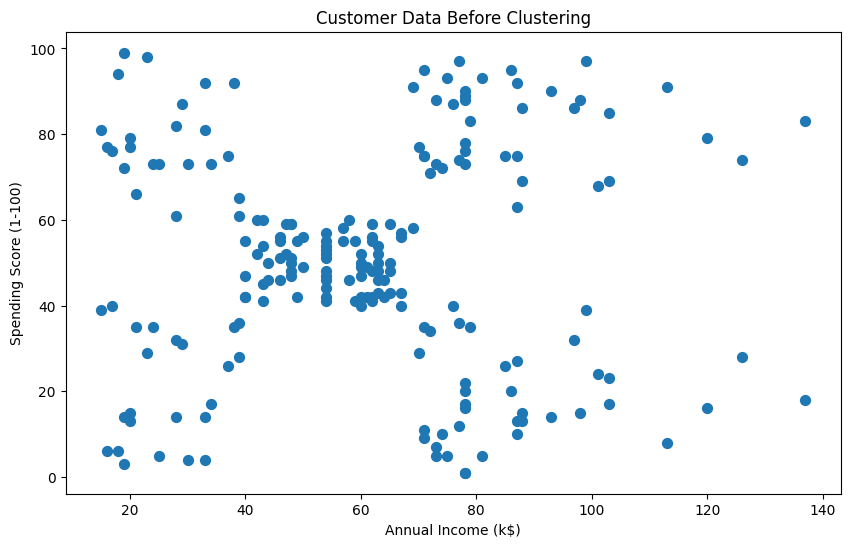

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    s=50
)

plt.title('Customer Data Before Clustering')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')

plt.show()

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [5]:
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
Duplicate rows: 0


In [6]:
print("\nNumerical statistics:")
display(df.describe())

print("\nGender distribution:")
print(df["Gender"].value_counts())


Numerical statistics:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



Gender distribution:
Gender
Female    112
Male       88
Name: count, dtype: int64


In [7]:
#Select features for clustering
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

print("Selected features:", X.columns.tolist())
display(X.head())

Selected features: ['Annual Income (k$)', 'Spending Score (1-100)']


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [8]:
#scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (200, 2)


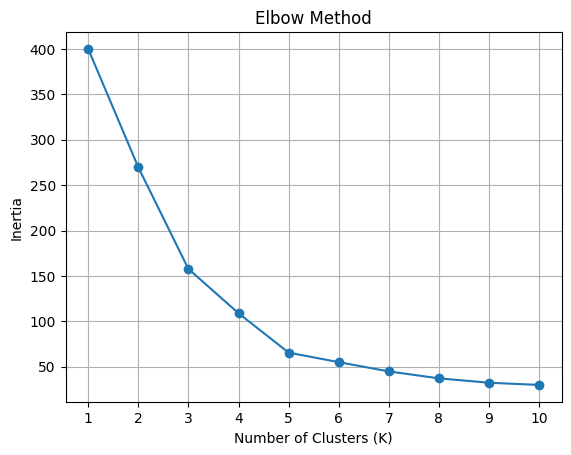

In [9]:
#find num of clustors
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10) #k-means
    model.fit(X_scaled) #train
    inertia.append(model.inertia_) #adds value to inertia list

plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [10]:
from sklearn.metrics import silhouette_score

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    print(f"K = {k}, Silhouette Score = {score:.3f}")

K = 2, Silhouette Score = 0.321
K = 3, Silhouette Score = 0.467
K = 4, Silhouette Score = 0.494
K = 5, Silhouette Score = 0.555
K = 6, Silhouette Score = 0.540
K = 7, Silhouette Score = 0.528
K = 8, Silhouette Score = 0.455
K = 9, Silhouette Score = 0.457
K = 10, Silhouette Score = 0.443


In [11]:
#train model
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Cluster sizes:")
print(df["Cluster"].value_counts().sort_index())

Cluster sizes:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


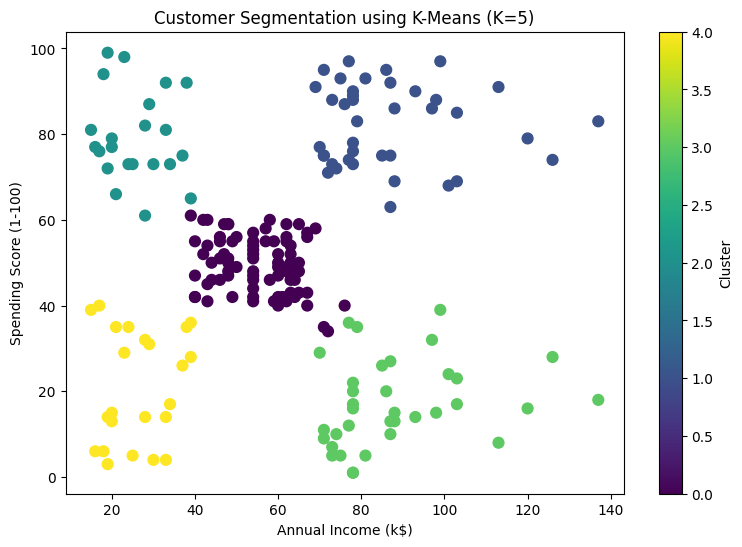

In [12]:
#visualize clustors
plt.figure(figsize=(9, 6))

plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    c=df["Cluster"],
    cmap="viridis",
    s=60
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customer Segmentation using K-Means (K=5)")
plt.colorbar(label="Cluster")
plt.show()


In [13]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, df["Cluster"])

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.555


In [14]:
print("========== CUSTOMER SEGMENTATION RESULTS(SUMMARY) ==========")
print("Dataset records:", len(df))
print("Number of clusters:", df["Cluster"].nunique())
print("Silhouette Score:", round(score, 3))

print("\nCustomers per cluster:")
print(df["Cluster"].value_counts().sort_index())

print("\nCluster averages:")
display(
    df.groupby("Cluster")[
        ["Annual Income (k$)", "Spending Score (1-100)"]
    ].mean().round(2)
)

========== CUSTOMER SEGMENTATION RESULTS(SUMMARY) ==========
Dataset records: 200
Number of clusters: 5
Silhouette Score: 0.555

Customers per cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Cluster averages:


,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


In [15]:
#test on new customer
new_customer = pd.DataFrame({
    "Annual Income (k$)": [85],
    "Spending Score (1-100)": [75]
})

new_customer_scaled = scaler.transform(new_customer)
cluster = kmeans.predict(new_customer_scaled)

print("Assigned Cluster:", cluster[0])

Assigned Cluster: 1


#MOVING TO DBSCAN (TO CHECK)


In [17]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.3, min_samples=5)

df["Cluster"] = dbscan.fit_predict(X_scaled)

print("========== CUSTOMER SEGMENTATION RESULTS ==========")
print("Dataset records:", len(df))

labels = df["Cluster"]
n_clusters = len(set(labels) - {-1})

print("Number of clusters:", n_clusters)
print("Number of noise points:", (labels == -1).sum())

print("\nCustomers per cluster:")
print(labels.value_counts().sort_index())

========== CUSTOMER SEGMENTATION RESULTS ==========
Dataset records: 200
Number of clusters: 7
Number of noise points: 35

Customers per cluster:
Cluster
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64


In [18]:
#check Sil score
from sklearn.metrics import silhouette_score

mask = labels != -1
cluster_labels = labels[mask]

if 2 <= cluster_labels.nunique() < len(cluster_labels):
    score = silhouette_score(X_scaled[mask], cluster_labels)
    print("\nSilhouette Score:", round(score, 3))
else:
    print("\nSilhouette Score cannot be calculated meaningfully.")


Silhouette Score: 0.524


In [19]:
print("\nCluster averages:")

print(
    df[df["Cluster"] != -1]
    .groupby("Cluster")[
        ["Annual Income (k$)", "Spending Score (1-100)"]
    ]
    .mean()
    .round(2)
)


Cluster averages:
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                     23.17                   74.58
1                     19.60                    6.60
2                     22.43                   34.43
3                     55.23                   48.58
4                     79.53                   83.13
5                     75.93                   10.07
6                     88.78                   17.00


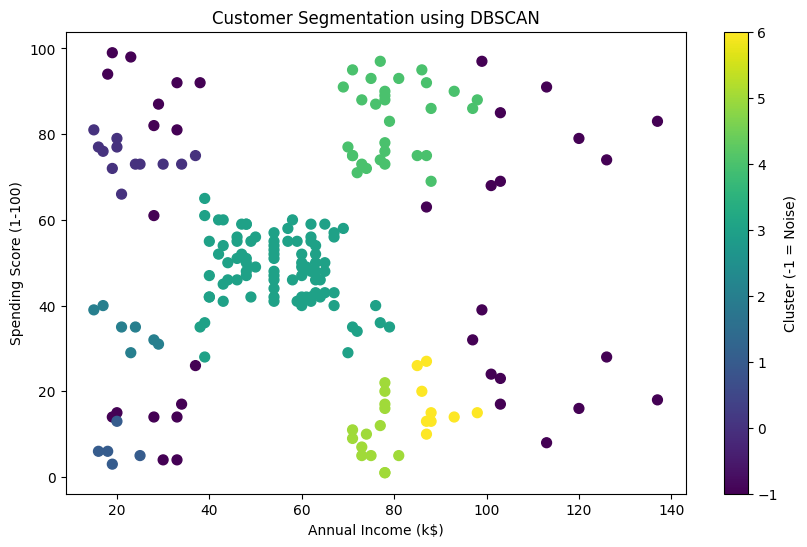

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    c=df["Cluster"],
    cmap="viridis",
    s=50
)

plt.title("Customer Segmentation using DBSCAN")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.colorbar(label="Cluster (-1 = Noise)")
plt.show()